# Job 51171824 — the depth arm, and the end of the barrier reading

Stage D handed an attention-only model more WIDTH than the hub (`d_model` 384
against 256) and it did not cross. **Stage E (`51171824`, 6/6)** hands it more
DEPTH instead: no MLP anywhere, at `L=8` and `L=12`, against a hub at `L=6`,
three seeds each and everything else at the hub's settings. Both depths were
chosen because the COMPLETE model is already measured there on this exact grid
and budget, so each rung has a paired partner at identical depth rather than an
extrapolation.

**E2 falsifies the barrier reading.** Attention-only at `L=12` lands at `rho_50`
0.605 on 3 of 3 crossing seeds, below the tie-break floor the stage E header
fixed in advance, at 1.47× fewer parameters than the hub and with no MLP
anywhere. Depth bought the MLP back where 1.5× the width did not.

Everything below is scored by `scripts/capacity_back.py`, which was written and
committed **before the deciding cells landed** and is pinned to the sbatch
headers by 15 tests. This notebook runs it; it does not restate its conclusions
in its own words. Section 5 gives `rho_50` before and after on the same eval.

In [1]:
import json, os, subprocess, sys
sys.path.insert(0, "/home/users/hshunt/spin_gnn")
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

REPO = "/home/users/hshunt/spin_gnn"
BOOT = 2000          # the programme's scoring default; CIs here match the scorers'
SEEDS = (0, 1, 2)    # every rung here is 3 seeds unless the table says otherwise

from scripts.minarch_analysis import SCAN_DEFAULT, SCAN_L6, SCAN_C, SCAN_D, SCAN_E
from scripts.capacity_back import (BARRIER_LO, BARRIER_HI, FREE, E2_CAPACITY,
                                   D2, E1, E2, FULL_L8, FULL_L12, NOMLP_L6)
from scripts.stagec_score import HUB, PLATEAU, S_RHO50, S_MEAN, escapes, rho_txt, rung, summarize
from notebooks.make_deptharm_deck import FULL_DEPTHS, NOMLP_DEPTHS, collect

# SCAN_E is read here and HAS to be -- it is the subject. It stays out of
# SCAN_DIRS, and so out of every other notebook, because its rungs carry
# entirely default hyperparameters and would pool into the s* that stages A-D
# were already scored against. s* is quoted frozen below and never recomputed:
# a new rung must not move the bar an existing verdict was measured with.
DIRS = [SCAN_DEFAULT, SCAN_L6, SCAN_C, SCAN_D, SCAN_E]

COMMIT = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=REPO,
                        capture_output=True, text=True).stdout.strip()
print("git commit        ", COMMIT)
print("branch            ", subprocess.run(["git", "rev-parse", "--abbrev-ref", "HEAD"],
                                           cwd=REPO, capture_output=True,
                                           text=True).stdout.strip())
print("bootstrap draws   ", BOOT)
print("frozen yardstick  ", f"s* = {S_RHO50} in rho_50, {S_MEAN} in mean_solve")
print("plateau           ", f"train NLL {PLATEAU} (finding 44)")
print("thresholds        ", f"E1 free at rho_50 <= {FREE:.3f}; E2 free at <= {E2_CAPACITY:.3f}; "
                            f"barrier band [{BARRIER_LO:.2f}, {BARRIER_HI:.2f}]")
for d in DIRS:
    print("scan dir          ", d)

git commit         3f86eb6
branch             sudoku-dd
bootstrap draws    2000
frozen yardstick   s* = 0.1484 in rho_50, 0.2918 in mean_solve
plateau            train NLL 1.64 (finding 44)
thresholds         E1 free at rho_50 <= 0.740; E2 free at <= 0.619; barrier band [0.72, 0.80]
scan dir           /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_2026-11-04
scan dir           /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_L6_2026-11-04
scan dir           /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_C_2026-11-04
scan dir           /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_D_2026-11-04
scan dir           /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_E_2026-11-04


## 1. Provenance: the config every rung was actually run with

Read off each cell's `config.json` rather than from the sbatch headers, because
stage D's header turned out to have mis-estimated its own parameter count by 4%.
The two ladders differ from the hub in exactly one field apiece — `num_layers`
for the complete ladder, `num_layers` and `arch_mode` for the attention-only
one — and the stage E rungs differ from the hub in `num_layers` and `arch_mode`
and nothing else.

In [2]:
cells = collect(DIRS, BOOT)
hub = summarize(rung(cells, HUB))
e1, e2, d2 = summarize(rung(cells, E1)), summarize(rung(cells, E2)), summarize(rung(cells, D2))
print(f"{len(cells)} cells on disk | E1 {e1['n']}/3 seeds, E2 {e2['n']}/3 seeds\n")

FIELDS = ("num_layers", "d_model", "dim_feedforward", "nhead", "arch_mode", "warmup_epochs",
          "lr", "batch_size", "n_train_instances", "epochs", "shuffle_adj", "fall",
          "n_nodes", "degree", "n_colors", "seed")
print(f"{'rung':<20}" + "".join(f"{f.replace('_', ' ')[:9]:>11}" for f in FIELDS[:6]))
print("-" * 86)
for tag, depths in (("full", FULL_DEPTHS), ("no_mlp", NOMLP_DEPTHS)):
    for L, key in depths:
        ms = rung(cells, key)
        if not ms:
            continue
        cfg = json.load(open(os.path.join(ms[0]["path"], "config.json")))
        print(f"{tag + ' L=' + str(L):<20}" + "".join(f"{str(cfg.get(f)):>11}" for f in FIELDS[:6]))
print()
cfg = json.load(open(os.path.join(rung(cells, HUB)[0]["path"], "config.json")))
print("held constant across every rung:",
      "  ".join(f"{f}={cfg.get(f)}" for f in FIELDS[8:-1]))
print("seeds per rung:", SEEDS, " (seed is the only thing that varies within a rung)")
for key, nm in ((E1, "E1 no_mlp L=8"), (E2, "E2 no_mlp L=12")):
    print(f"  {nm:<16}" + "  ".join(
        f"seed {json.load(open(os.path.join(m['path'], 'config.json')))['seed']}"
        for m in rung(cells, key)))

78 cells on disk | E1 3/3 seeds, E2 3/3 seeds

rung                  num layer    d model  dim feedf      nhead  arch mode  warmup ep
--------------------------------------------------------------------------------------
full L=1                      1        256       1024          4       full          0
full L=2                      2        256       1024          4       full          0
full L=3                      3        256       1024          4       full          0
full L=4                      4        256       1024          4       full          0
full L=6                      6        256       1024          4       full          0
full L=8                      8        256       1024          4       full          0
full L=12                    12        256       1024          4       full          0
no_mlp L=4                    4        256       1024          4     no_mlp          0
no_mlp L=6                    6        256       1024          4     no_mlp        

## 2. The metrics table

`rho_50` is the realized hint density at which the solve rate crosses 0.5 on a
14-point × 400-instance leak-free grid — **lower is better** — and it CENSORS
once no bin clears 0.5. `mean_solve` is the unweighted mean over the 14 bins and
never censors, which is why censored rungs are still readable here.

The `esc` column decides how a row may be *worded*: it counts seeds that
finished below the 1.64 train-NLL plateau. A rung at 0/3 did not train in 375k
steps and is never evidence about depth in either direction — the named way
stage E could have produced nothing, written into the header before it ran.

In [3]:
LADDERS = ([("full", L, k) for L, k in FULL_DEPTHS] +
           [("no_mlp", L, k) for L, k in NOMLP_DEPTHS])

print(f"{'rung':<16}{'rho_50':>10}{'mean_solve':>12}{'spread':>9}"
      f"{'trainable':>12}{'esc':>6}{'cross':>7}   train NLL per seed")
print("-" * 112)
for tag, L, key in LADDERS:
    ms = rung(cells, key)
    if not ms:
        print(f"{tag + ' L=' + str(L):<16}   (nothing on disk yet)")
        continue
    s, (n_esc, nll) = summarize(ms), escapes(ms)
    rho = f"{s['rho50']:.3f}" if s["rho50_readable"] else "CENSORED"
    spr = f"{s['spread_mean']:.4f}" if s["spread_mean"] == s["spread_mean"] else "-"
    cross = sum(1 for m in ms if m["flag"] == "ok")
    print(f"{tag + ' L=' + str(L):<16}{rho:>10}{s['mean_solve']:>12.4f}{spr:>9}"
          f"{s['trainable']:>12,}{n_esc:>4}/{s['n']}{cross:>5}/{s['n']}   "
          + "/".join(f"{v:.3f}" for v in nll))
print()
print(f"the hub (full L=6) is the paired control for the arm: rho_50 {hub['rho50']:.3f}, "
      f"mean_solve {hub['mean_solve']:.4f}, {hub['trainable']:,} trainable")
print(f"E1's partner at identical depth is full L=8; E2's is full L=12. Neither is an "
      f"extrapolation:\nboth were measured on this grid and budget before stage E was written.")

rung                rho_50  mean_solve   spread   trainable   esc  cross   train NLL per seed
----------------------------------------------------------------------------------------------------------------
full L=1          CENSORED      0.0211   0.0062     951,098   0/3    0/3   2.452/2.451/2.459
full L=2             0.919      0.0807   0.0502   1,740,858   0/3    3/3   1.688/1.688/1.756
full L=3             0.757      0.3102   0.0071   2,530,618   3/3    3/3   1.606/1.607/1.605
full L=4             0.763      0.3084   0.2784   3,320,378   3/3    2/3   1.566/1.617/1.573
full L=6             0.592      0.5389   0.0141   4,899,898   3/3    3/3   1.524/1.528/1.530
full L=8             0.471      0.7111   0.2205   6,479,418   3/3    3/3   1.501/1.518/1.505
full L=12            0.385      0.8163   0.1530   9,638,458   3/3    3/3   1.494/1.495/1.501
no_mlp L=4           0.921      0.0796   0.2804   1,218,106   0/3    2/3   1.661/1.702/1.709
no_mlp L=6           0.763      0.3039   0.2671  

## 3. The pre-registered scorer, run as it was committed

`scripts/capacity_back.py` transcribes every threshold from the stage D and
stage E sbatch headers, checks trainability FIRST, and refuses to score a rung
with fewer than three seeds. Its branch order is itself registered and pinned by
`tests/test_capacity_back.py`.

Two things in its output were registered to be reported *ahead* of the verdict:

* **E4**, the free out-of-sample sufficiency test. Every rung not on the depth
  ladder is held out and asked whether its solve rate sits on the curve that
  maps token accuracy to solving. If stage E's rungs had missed that curve, the
  accuracy-is-sufficient result would have been the headline instead.
* **the contradiction inside the registration itself** — the stage E header's
  tie-break sends any median in [0.72, 0.740] to the barrier reading, while its
  falsifier kills that reading for any median below 0.740 on ≥2 of 3 crossing
  seeds. The scorer prints both readings rather than quietly picking one. E2's
  0.605 is below the overlap, so the falsifier fires unambiguously.

In [4]:
out = subprocess.run([sys.executable, "-m", "scripts.capacity_back", "--boot", str(BOOT)],
                     cwd=REPO, capture_output=True, text=True)
print(out.stdout)
if out.returncode:
    print("STDERR:", out.stderr[-2000:])

STAGES D AND E: giving an ablated model capacity back, on two axes
  78 cells read from 5 directories (SCAN_E added by hand; it is out of SCAN_DIRS on purpose)
  frozen bar s* = 0.1484 rho_50 / 0.2918 mean_solve, NOT recomputed
  hub (L=6 d256 ff1024 h4 full): rho_50 0.592  mean_solve 0.5389  4,899,898 trainable
  (A) BARRIER window [0.72, 0.80];  falsified only by a median below 0.72 on >=2 of 3 crossing seeds

PAIRED REFERENCE RUNGS, all at this exact budget and grid:
  full L=8 (E1's depth partner)      rho_50    0.471   mean_solve 0.7111   6,479,418 trainable
  full L=12 (E2's depth partner)     rho_50    0.385   mean_solve 0.8163   9,638,458 trainable
  no_mlp L=6 d256 (the single knob)  rho_50    0.763   mean_solve 0.3039   1,746,490 trainable

=== D1 -- bisect the width cliff, full d192 ===
  3/3 seeds on disk, 3/3 crossed 0.5
  rho_50 median 0.752   (hub 0.592)
  mean_solve median 0.3266 [spread 0.0268]   (hub 0.5389)
  trainable 3,381,562   (hub 4,899,898)
  plateau escapes 3/

## 4. The two depth ladders, and where the stage E rungs landed

The same figures as pages 4 and 5 of the slide deck, drawn by the deck's own
code so the two cannot drift apart.

A hollow marker means the rung never escaped the plateau. Censored rungs cannot
be placed on a `rho_50` axis and are omitted from the second figure; all of them
sit BELOW the band, so omitting them understates the pile-up rather than
flattering it.

full L=8  (E1's partner)  rho_50    0.471  mean_solve 0.7111   6,479,418 trainable
E1 no_mlp L=8            rho_50    0.749  mean_solve 0.3214   2,274,874 trainable
full L=12 (E2's partner)  rho_50    0.385  mean_solve 0.8163   9,638,458 trainable
E2 no_mlp L=12           rho_50    0.605  mean_solve 0.5214   3,331,642 trainable

the attention-only ladder keeps descending with depth; it does not flatten at the band,
which is what the barrier reading required of it


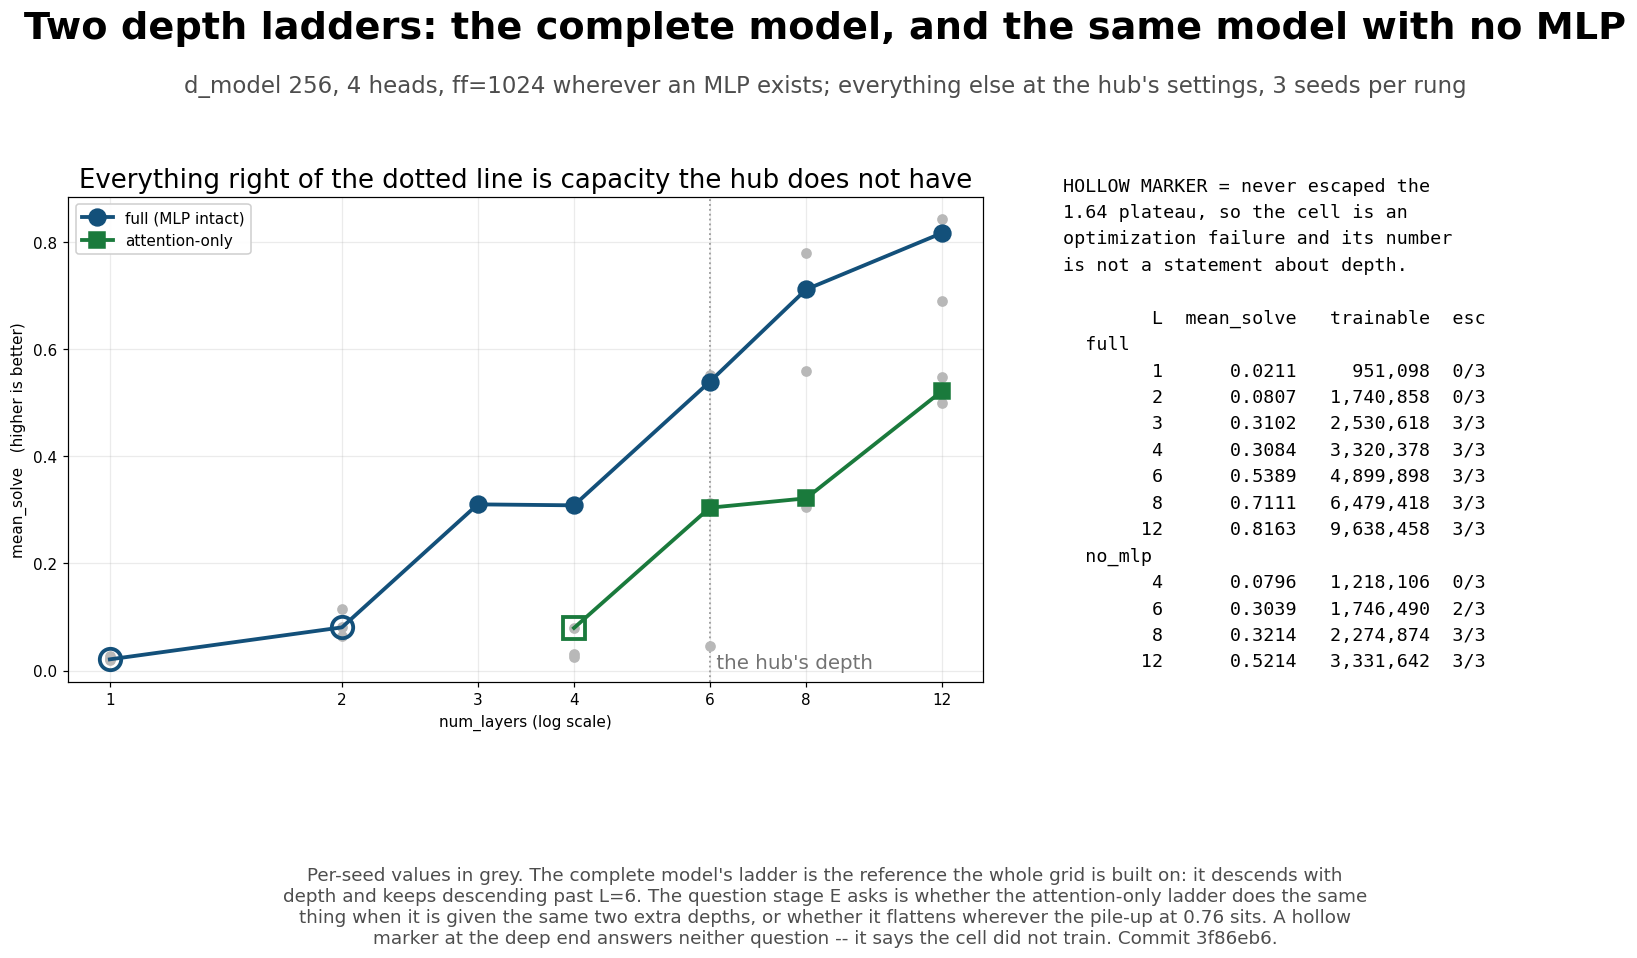

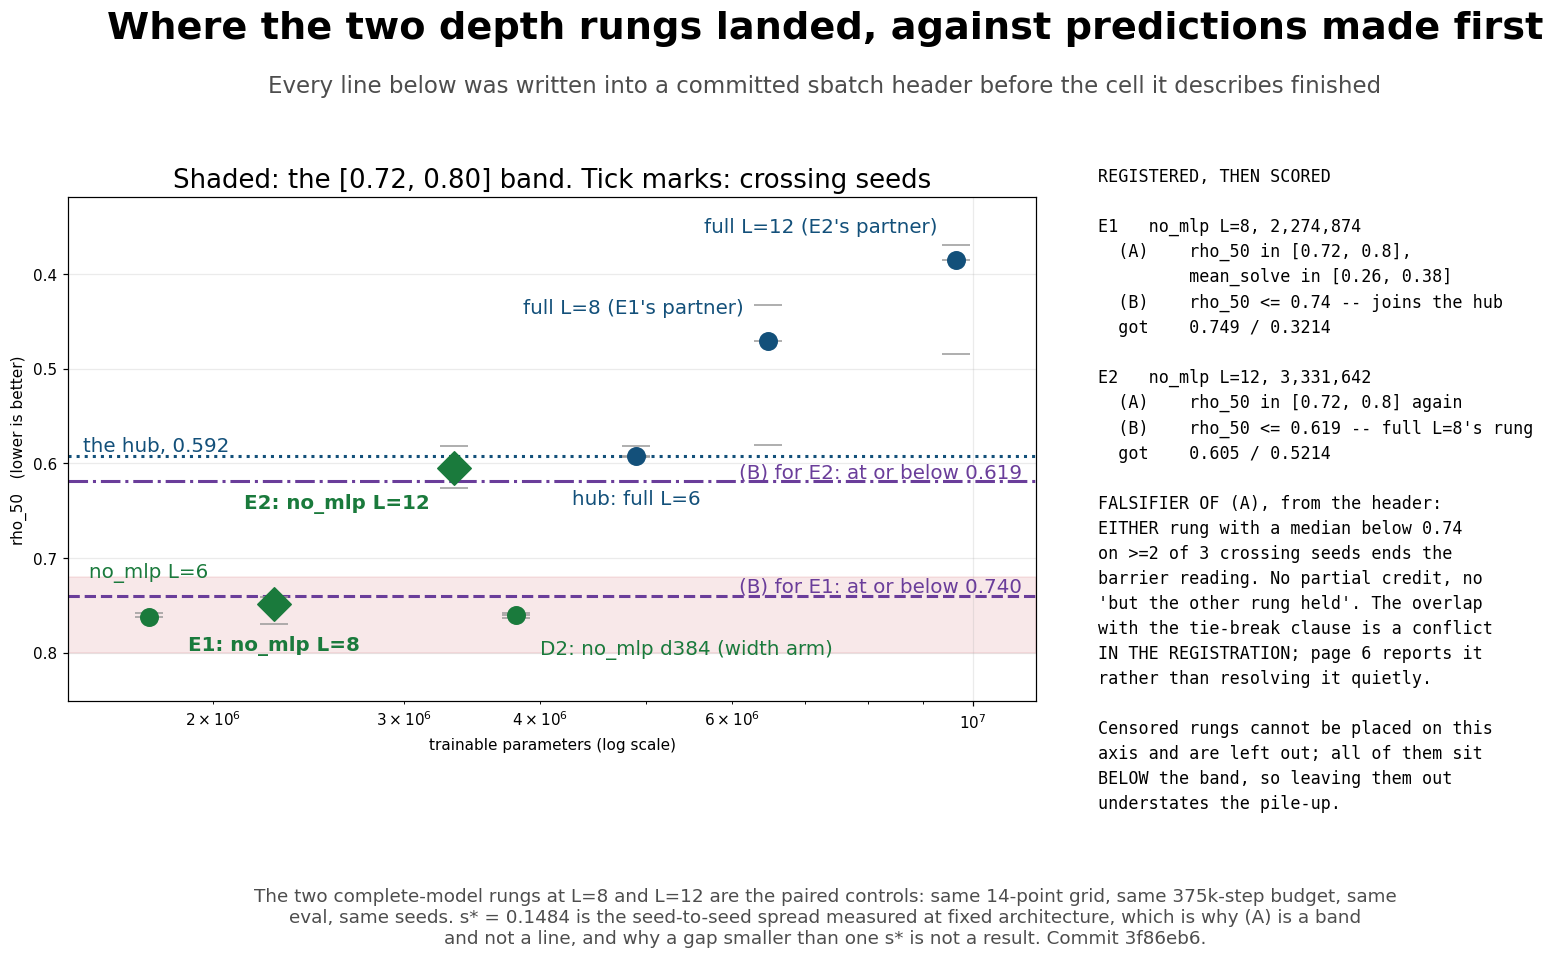

In [5]:
from notebooks.make_deptharm_deck import page_ladders, page_band


class Keep:
    """A PdfAndPng stand-in that keeps the figure open for the notebook."""

    def savefig(self, fig):
        pass


page_ladders(Keep(), cells, COMMIT)
page_band(Keep(), cells, e1, e2, hub, COMMIT)

for nm, s in (("full L=8  (E1's partner)", summarize(rung(cells, FULL_L8))),
              ("E1 no_mlp L=8          ", e1),
              ("full L=12 (E2's partner)", summarize(rung(cells, FULL_L12))),
              ("E2 no_mlp L=12         ", e2)):
    print(f"{nm}  rho_50 {rho_txt(s):>8}  mean_solve {s['mean_solve']:.4f}  "
          f"{s['trainable']:>10,} trainable")
print("\nthe attention-only ladder keeps descending with depth; it does not flatten at the "
      "band,\nwhich is what the barrier reading required of it")

## 5. `rho_50` before and after, on the same eval

The eval is unchanged — the same 14-point × 400-instance leak-free grid, the
same 375k-step budget, `--shuffle-adj --fall` throughout, and the same frozen
seed-spread bar `s*` = 0.1484 / 0.2918, which was fixed before any of these
cells ran and is not recomputed here. So these numbers are directly comparable
to every earlier rung.

The brief since 2026-11-04 is the SMALLEST architecture that still learns direct
deduction, so the figure of merit is the standing minimum. The rule for
replacing it was fixed in stage H's sbatch header **before E2 was scored**: a
rung takes the standing minimum only on 3 of 3 crossing seeds AND a median
`rho_50` at or below 0.740.

**E2 is the first rung ever to satisfy it, and it costs size to do so.** That is
stated plainly below rather than buried: `rho_50` improved by more than one
`s*`, and the parameter count went the wrong way.

In [6]:
from scripts.rung_collapse import BAND_HI

prev = summarize(rung(cells, NOMLP_L6))          # the standing minimum before today
prev_cross = sum(1 for m in rung(cells, NOMLP_L6) if m["flag"] == "ok")
now_cross = sum(1 for m in rung(cells, E2) if m["flag"] == "ok")

print("THE STANDING MINIMUM, BEFORE AND AFTER -- same grid, same budget, same eval")
print(f"  {'rung':<22}{'rho_50':>9}{'mean_solve':>12}{'trainable':>12}{'cross':>8}{'esc':>6}")
print("  " + "-" * 69)
for tag, s, key, cr in (("BEFORE  no_mlp L=6", prev, NOMLP_L6, prev_cross),
                        ("AFTER   no_mlp L=12", e2, E2, now_cross)):
    n_esc, _ = escapes(rung(cells, key))
    print(f"  {tag:<22}{rho_txt(s):>9}{s['mean_solve']:>12.4f}{s['trainable']:>12,}"
          f"{cr:>5}/{s['n']}{n_esc:>4}/{s['n']}")
print()
print(f"  rho_50 fell {prev['rho50'] - e2['rho50']:.3f} "
      f"({(prev['rho50'] - e2['rho50']) / S_RHO50:.2f} s*), and all three seeds now cross "
      f"where two did before.")
print(f"  Parameters ROSE {e2['trainable'] / prev['trainable']:.2f}x "
      f"({prev['trainable']:,} -> {e2['trainable']:,}). Stage H (51223007) is the attempt to "
      f"give that back.")
print(f"  Against the hub (full L=6): {hub['trainable'] / e2['trainable']:.2f}x fewer "
      f"parameters, rho_50 {e2['rho50'] - hub['rho50']:+.3f} "
      f"({(e2['rho50'] - hub['rho50']) / S_RHO50:.2f} s*) -- inside the seed spread.")

# "Still solves" is the band criterion the rest of the programme uses: a
# complete 3-seed rung whose median rho_50 is readable and no worse than the
# band's upper edge. Picking the smallest readable rung instead would promote a
# cell that crosses only at the very top of the grid.
solving = []
for key in set(k[:-1] for k in cells):
    s = summarize(rung(cells, key))
    if s["n"] >= 3 and s["rho50_readable"] and s["rho50"] <= BAND_HI:
        solving.append((key, s))
best = sorted(solving, key=lambda kv: kv[1]["rho50"])


def name(key):
    if len(key) == 3:
        return f"L={key[0]} {key[2]}"
    L, h, arch, d, ff, wu = key[:6]
    bits = [f"L={L}", arch] + ([f"h{h}"] if h != 4 else []) + ([f"d{d}"] if d != 256 else [])
    bits += ([f"ff{ff}"] if ff != 1024 else []) + ([f"wu{wu}"] if wu else [])
    return " ".join(bits + ([f"ep{key[6]}"] if len(key) == 7 else []))


print()
print("BEST SOLVER ON THIS EVAL AT ANY SIZE -- unchanged by stage E, and nothing here "
      "was trying to move it")
print(f"  {'rung':<20}{'rho_50':>9}{'mean_solve':>12}{'trainable':>12}")
print("  " + "-" * 53)
for i, (key, s) in enumerate(best[:5]):
    tag = ("   <- best solver" if i == 0 else
           "   <- the hub, paired control" if key == HUB else
           "   <- E2, the new standing minimum" if key == E2 else "")
    print(f"  {name(key):<20}{s['rho50']:>9.3f}{s['mean_solve']:>12.4f}{s['trainable']:>12,}{tag}")
print()
print(f"  E2 is {best[0][1]['trainable'] / e2['trainable']:.1f}x smaller than the best solver "
      f"and {e2['rho50'] - best[0][1]['rho50']:+.3f} worse in rho_50. No improvement in solving "
      f"is claimed;\n  the claim is that an ablated architecture reached the hub's rho_50, "
      f"which is a statement about what the MLP was for.")

THE STANDING MINIMUM, BEFORE AND AFTER -- same grid, same budget, same eval
  rung                     rho_50  mean_solve   trainable   cross   esc
  ---------------------------------------------------------------------
  BEFORE  no_mlp L=6        0.763      0.3039   1,746,490    2/3   2/3
  AFTER   no_mlp L=12       0.605      0.5214   3,331,642    3/3   3/3

  rho_50 fell 0.158 (1.06 s*), and all three seeds now cross where two did before.
  Parameters ROSE 1.91x (1,746,490 -> 3,331,642). Stage H (51223007) is the attempt to give that back.
  Against the hub (full L=6): 1.47x fewer parameters, rho_50 +0.013 (0.09 s*) -- inside the seed spread.

BEST SOLVER ON THIS EVAL AT ANY SIZE -- unchanged by stage E, and nothing here was trying to move it
  rung                   rho_50  mean_solve   trainable
  -----------------------------------------------------
  L=12 full               0.385      0.8163   9,638,458   <- best solver
  L=8 full                0.471      0.7111   6,479,418
  L

## 6. What this does not settle, and what is still running

**The resolution limit stands whatever section 3 says.** `scripts/rung_collapse.py`
found no DETECTABLE separation between architecture labels inside the band
(p = 0.569, against a positive control at p = 0.045 on a separation 26× larger).
"No detectable separation" is not "the architectures are equivalent", and E2
crossing below the floor does not retroactively give that test power.

**`51194118` stage G** moves the one knob stage E held fixed: the training
budget. It reruns attention-only at d128 and d256 for 100 epochs instead of 50,
with an epoch-50 reproduction gate — the first 50 epochs must match the frozen
50-epoch twins to within 0.01 nats or the cells are not twins and nothing is
comparable. It is the only route by which a rung written off here as "did not
train" can come back. `scripts/escape_timing.py` Q3 predicts it will fail: there
is no knee, and extrapolating the 39 never-escaping cells at their own last-20%
slope puts the median 87 epochs short. That contradiction with stage G's own
header is on record in both.

**`51223007` stage H** moves exactly one knob from E2: width, at d128 and d192
with L=12 and no MLP, three seeds each. If depth is the currency and width is
not a separate floor, H1 at 879,418 trainable crosses at or below 0.740 and
becomes a standing minimum 5.6× below the hub. Two contradictory trainability
predictions are registered against it — monotone-depth says ≥2/3 seeds escape,
`escape_timing.py` Q3 says 0/3 — and one of them is wrong in print.

**Stage F**, a 3-seed replicate at N=96, is still unwritten on purpose. It would
now replicate E2 rather than the hub, and whether it replicates E2 or whatever
stage H leaves standing depends on numbers that do not exist yet.